# Surgery risk: exploratory analysis

**Target:** P(lumbar spine surgery while still covered, within (t, t + 12 months] | eligible at t)

- **Index dates t:** quarterly from 2024-07-01 to 2025-07-01. Each has a full 12-month lookback (data starts 2023-07-01) and a full 12-month horizon (extract is 2026-07-01).
- **Eligible at t:**
  - covered on t,
  - a back pain (LBP) encounter before t,
  - no surgery before t,
  - no surgical consult in the 90 days before t (late-stage patients are excluded).
- **Surgery:** an EHR `Spine Surgery` event that is `Performed` **or has a null status**, or a PAID claim for 22630 / 22633 / 63030 / 63047. Null-status surgeries match paid surgery claims at the same rate as Performed ones (64% vs 74% of patients, dated 0–2 days apart), while `Scheduled` ones match about 2%, the same as `Cancelled`.
- **Leaving coverage is a competing event, not censoring.** Meridian only pays for surgeries while a patient is attributed, so the target counts surgeries before `coverage_end`. A patient who leaves without surgery counts as a zero. Every index date has its full horizon before the extract, so there is no other censoring, and P is simply the share of snapshots with a surgery while covered.
- **Kaplan–Meier (`p_km`)** is shown alongside for comparison. It treats leaving as censoring, which estimates the risk *if the patient had stayed covered*: the clinical number, not the one Meridian pays for.
- **Segment features:** computed over the 12 months before t.

The unit is a *patient-snapshot*: one patient can appear on several index dates, so pooled confidence intervals are somewhat too narrow.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data")
EXTRACT = pd.Timestamp("2026-07-01")
INDEX_DATES = pd.date_range("2024-07-01", "2025-07-01", freq="QS")
HORIZON_DAYS = 365
LOOKBACK = pd.Timedelta(days=365)
LATE_STAGE_WINDOW = pd.Timedelta(days=90)
SURGERY_CPT = ["22630", "22633", "63030", "63047"]

pd.set_option("display.float_format", "{:.4f}".format)

## Load

In [2]:
patients = pd.read_csv(
    DATA / "meridian_health_patients.csv", dtype={"zip3": str}, parse_dates=["coverage_start", "coverage_end"]
)
encounters = pd.read_csv(DATA / "meridian_health_encounters.csv", parse_dates=["event_date"])
enrollments = pd.read_csv(DATA / "meridian_health_enrollments.csv", parse_dates=["enrollment_date"])
claims = pd.read_csv(
    DATA / "data_web_claims.csv.gz",
    dtype={"code": str},
    usecols=["patient_token", "service_date", "code", "claim_status"],
    parse_dates=["service_date"],
)

patients["birth_year"] = patients.birth_year.mask(patients.birth_year == 1900)  # placeholder value
patients["coverage_end"] = patients.coverage_end.fillna(EXTRACT)
patients["sex"] = patients.sex.fillna("Missing")
claims = claims[claims.claim_status.isin(["PAID", "DISPENSED"])]
# Stale "Scheduled" and null statuses are kept as having occurred; only explicit Cancelled / No Show are dropped.
occurred = encounters[~encounters.event_status.isin(["Cancelled", "No Show"])]

surgery_dates = pd.concat(
    [
        encounters.loc[
            # Null-status surgeries behave like Performed ones in the claims; Scheduled ones behave like Cancelled.
            (encounters.event_category == "Spine Surgery")
            & (encounters.event_status.eq("Performed") | encounters.event_status.isna()),
            ["patient_token", "event_date"],
        ],
        claims.loc[claims.code.isin(SURGERY_CPT), ["patient_token", "service_date"]].rename(
            columns={"service_date": "event_date"}
        ),
    ]
)
first_surgery = surgery_dates.groupby("patient_token").event_date.min()
first_lbp = occurred[occurred.event_category == "LBP Encounter"].groupby("patient_token").event_date.min()

## Build the snapshot panel

In [3]:
CONDITIONS = {
    "diabetes": ["E11.9"],
    "hypertension": ["I10"],
    "heart_disease": ["I25.10"],
    "copd": ["J44.9"],
    "ckd": ["N18.3"],
    "depression_anxiety": ["F32.9", "F41.1"],
    "smoker": ["F17.210"],
    "osteoporosis": ["M81.0"],
}
SPINE_DX = {
    "radiculopathy": ["M54.16", "M54.17"],
    "stenosis": ["M48.061", "M48.062"],
    "neurogenic_claudication": ["M48.062"],
    "spondylolisthesis": ["M43.16"],
    "disc_degeneration": ["M51.36"],
}
# Z68.1 = BMI <= 19.9, Z68.2x/3x = 20-39 by unit, Z68.41/42 = 40-44.9 / 45-49.9 (midpoints used).
Z68_BMI = {"Z68.1": 19, "Z68.41": 42, "Z68.42": 47} | {f"Z68.{n}": n for n in range(20, 40)}
STAGE_ORDER = {"LBP Encounter": 0, "Imaging": 1, "PT Referral": 2, "Injection": 3, "Surgical Consult": 4}
STAGE_LABELS = ["0 LBP only", "1 Imaging", "2 PT referral", "3 Injection", "4 Consult (>90d ago)"]
PT_CPT = ["97110", "97140", "97530"]


def snapshot(t: pd.Timestamp) -> pd.DataFrame:
    p = patients.set_index("patient_token")
    p = p[(p.coverage_start <= t) & (p.coverage_end > t)]
    recent_consult = occurred.loc[
        (occurred.event_category == "Surgical Consult") & occurred.event_date.between(t - LATE_STAGE_WINDOW, t, inclusive="left"),
        "patient_token",
    ]
    p = p[
        (first_lbp.reindex(p.index) < t).to_numpy()
        & ~(first_surgery.reindex(p.index) < t).to_numpy()
        & ~p.index.isin(recent_consult)
    ]

    follow = (p.coverage_end.clip(upper=EXTRACT) - t).dt.days.clip(upper=HORIZON_DAYS)
    to_surgery = (first_surgery.reindex(p.index) - t).dt.days
    event = to_surgery.le(follow)

    enc = occurred[occurred.event_date.between(t - LOOKBACK, t, inclusive="left")]
    clm = claims[claims.service_date.between(t - LOOKBACK, t, inclusive="left")]
    codes = pd.concat([enc[["patient_token", "event_code"]].rename(columns={"event_code": "code"}), clm[["patient_token", "code"]]])

    def has(values: list[str]) -> np.ndarray:
        return p.index.isin(codes.loc[codes.code.isin(values), "patient_token"])

    bmi = clm[clm.code.isin(Z68_BMI)].sort_values("service_date").groupby("patient_token").code.last().map(Z68_BMI)
    stage = enc.assign(s=enc.event_category.map(STAGE_ORDER)).groupby("patient_token").s.max()

    out = pd.DataFrame(
        {
            "index_date": t,
            "time": to_surgery.where(event, follow),
            "event": event,
            "age": t.year - p.birth_year,
            "sex": p.sex,
            "bmi": bmi.reindex(p.index),
            "obesity_dx": has(["E66.9", "E66.01"]),
            "stage": stage.reindex(p.index),
            "months_since_first_lbp": (t - first_lbp.reindex(p.index)).dt.days / 30.4,
            "mri": has(["72148"]),
            "injection": has(["62323", "64483"]),
            "pt_claims": has(PT_CPT),
            "prior_program": p.index.isin(
                enrollments.loc[enrollments.enrollment_date.between(t - LOOKBACK, t, inclusive="left"), "patient_token"]
            ),
            **{k: has(v) for k, v in CONDITIONS.items()},
            **{k: has(v) for k, v in SPINE_DX.items()},
        },
        index=p.index,
    )
    return out


panel = pd.concat([snapshot(t) for t in INDEX_DATES]).reset_index()
panel["age_band"] = pd.cut(panel.age, [0, 65, 70, 75, 80, 200], right=False, labels=["<65", "65-69", "70-74", "75-79", "80+"])
panel["bmi_band"] = pd.cut(panel.bmi, [0, 25, 30, 35, 40, 100], right=False, labels=["<25", "25-29", "30-34", "35-39", "40+"])
panel["bmi_band"] = panel.bmi_band.cat.add_categories("No BMI").fillna("No BMI")
panel["stage_label"] = pd.Categorical.from_codes(panel.stage.fillna(-1).astype(int) + 1, ["No activity in 12m"] + STAGE_LABELS)
panel["n_conditions"] = pd.cut(
    panel[list(CONDITIONS)].sum(axis=1), [0, 1, 2, 3, 99], right=False, labels=["0", "1", "2", "3+"]
)
panel["lbp_tenure"] = pd.cut(
    panel.months_since_first_lbp, [0, 3, 6, 12, 24, 99], right=False, labels=["<3m", "3-6m", "6-12m", "12-24m", "24m+"]
)
print(f"{len(panel):,} patient-snapshots, {panel.patient_token.nunique():,} patients, {int(panel.event.sum()):,} surgeries")
panel.groupby("index_date").agg(n=("event", "size"), surgeries=("event", "sum"))

80,580 patient-snapshots, 22,770 patients, 2,310 surgeries


,n,surgeries
index_date,,
2024-07-01,10787,405
2024-10-01,14002,471
2025-01-01,16853,504
2025-04-01,18952,499
2025-07-01,19986,431


## Helpers

- `rate` returns the share of snapshots with a surgery while covered (the target), with a normal-approximation 95% CI.
- `km` returns 1 − Kaplan–Meier survival with a Greenwood 95% CI. It treats leaving coverage as censoring and is only used for comparison.

In [4]:
def km_curve(time: pd.Series, event: pd.Series) -> pd.DataFrame:
    d = pd.DataFrame({"time": time, "event": event}).groupby("time").event.agg(events="sum", n="size")
    d["at_risk"] = d.n[::-1].cumsum()[::-1]
    d["surv"] = (1 - d.events / d.at_risk).cumprod()
    d["greenwood"] = (d.events / (d.at_risk * (d.at_risk - d.events))).cumsum()
    return d


def km(time: pd.Series, event: pd.Series) -> tuple[float, float, float]:
    d = km_curve(time, event)
    s = d.surv.iloc[-1]
    se = s * np.sqrt(d.greenwood.iloc[-1])
    return 1 - s, max(1 - s - 1.96 * se, 0), 1 - s + 1.96 * se


def rate(event: pd.Series) -> tuple[float, float, float]:
    p, n = event.mean(), len(event)
    half = 1.96 * np.sqrt(p * (1 - p) / n)
    return p, max(p - half, 0), p + half


def risk_by(df: pd.DataFrame, cols: str | list[str]) -> pd.DataFrame:
    cols = [cols] if isinstance(cols, str) else cols
    rows = []
    for key, g in df.groupby(cols, observed=True):
        p, lo, hi = rate(g.event)
        rows.append(
            {
                **dict(zip(cols, key)),
                "n": len(g),
                "surgeries": int(g.event.sum()),
                "p_12m": p,
                "ci_low": lo,
                "ci_high": hi,
                "p_km": km(g.time, g.event)[0],
            }
        )
    out = pd.DataFrame(rows)
    for c in cols:
        out[c] = out[c].astype(df[c].dtype)  # keep category order through pivots
    out["relative_risk"] = out.p_12m / OVERALL
    return out


def plot_risk(table: pd.DataFrame, col: str, title: str | None = None) -> None:
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(table) + 1))
    y = table[col].astype(str)
    ax.barh(y, table.p_12m * 100, xerr=[(table.p_12m - table.ci_low) * 100, (table.ci_high - table.p_12m) * 100], color="#4C78A8", capsize=3)
    ax.axvline(OVERALL * 100, color="grey", ls="--", lw=1, label=f"overall {OVERALL:.1%}")
    for i, (p, n) in enumerate(zip(table.p_12m, table.n)):
        ax.text(0.1, i, f"{p:.1%}  (n={n:,})", va="center", color="white", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("12-month surgery risk (%)")
    ax.set_title(title or col)
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()


def risk_grid(df: pd.DataFrame, rows: str, cols: str, min_n: int = 200):
    t = risk_by(df, [rows, cols])
    p = t.pivot(index=rows, columns=cols, values="p_12m")
    n = t.pivot(index=rows, columns=cols, values="n")
    display(n.fillna(0).astype(int).style.set_caption(f"n: {rows} x {cols}"))
    return (p.where(n >= min_n) * 100).style.format("{:.1f}%", na_rep="-").background_gradient(cmap="Reds", axis=None).set_caption(
        f"12-month surgery risk: {rows} x {cols} (cells with n < {min_n} hidden)"
    )


def flag_table(df: pd.DataFrame, flags: list[str]) -> pd.DataFrame:
    rows = []
    for f in flags:
        yes, no = df[df[f]], df[~df[f]]
        p_yes, p_no = yes.event.mean(), no.event.mean()
        rows.append({"flag": f, "prevalence": df[f].mean(), "n_yes": len(yes), "p_yes": p_yes, "p_no": p_no, "risk_ratio": p_yes / p_no})
    return pd.DataFrame(rows).sort_values("risk_ratio", ascending=False)

## Overall

In [5]:
OVERALL, lo, hi = rate(panel.event)
km_p, km_lo, km_hi = km(panel.time, panel.event)
complete = panel[(panel.time >= HORIZON_DAYS) | panel.event]
left = (~panel.event & (panel.time < HORIZON_DAYS)).mean()
print(f"Target, surgery while covered (leaving = competing event): {OVERALL:.2%} (95% CI {lo:.2%}-{hi:.2%})")
print(f"Kaplan-Meier, leaving = censoring (risk if stayed covered): {km_p:.2%} (95% CI {km_lo:.2%}-{km_hi:.2%})")
print(f"Complete-case rate, leavers dropped (wrong under both framings): {complete.event.mean():.2%}")
print(f"Share of snapshots that leave coverage before 12 months without surgery: {left:.1%}")

Target, surgery while covered (leaving = competing event): 2.87% (95% CI 2.75%-2.98%)
Kaplan-Meier, leaving = censoring (risk if stayed covered): 3.02% (95% CI 2.89%-3.14%)
Complete-case rate, leavers dropped (wrong under both framings): 3.36%
Share of snapshots that leave coverage before 12 months without surgery: 14.7%


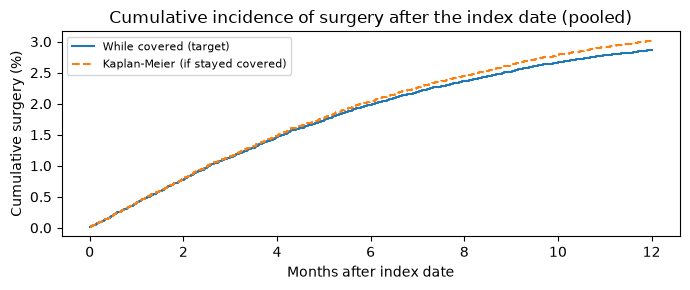

In [6]:
curve = km_curve(panel.time, panel.event)
cif = panel[panel.event].groupby("time").size().cumsum() / len(panel)
fig, ax = plt.subplots(figsize=(7, 3))
ax.step(cif.index / 30.4, cif * 100, where="post", label="While covered (target)")
ax.step(curve.index / 30.4, (1 - curve.surv) * 100, where="post", ls="--", label="Kaplan-Meier (if stayed covered)")
ax.set_xlabel("Months after index date")
ax.set_ylabel("Cumulative surgery (%)")
ax.set_title("Cumulative incidence of surgery after the index date (pooled)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### By index date

This checks whether the target is stable over time. The cohort is closed (nobody joins after 2025-04), so later snapshots are older and more heavily filtered: anyone who already had surgery is excluded.

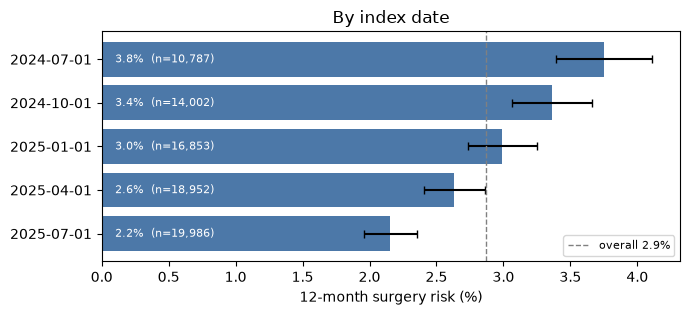

,index_date,n,surgeries,p_12m,ci_low,ci_high,p_km,relative_risk
0,2024-07-01,10787,405,0.0375,0.0340,0.0411,0.0392,1.3097
1,2024-10-01,14002,471,0.0336,0.0307,0.0366,0.0351,1.1734
2,2025-01-01,16853,504,0.0299,0.0273,0.0325,0.0314,1.0432
3,2025-04-01,18952,499,0.0263,0.0241,0.0286,0.0277,0.9185
4,2025-07-01,19986,431,0.0216,0.0196,0.0236,0.0229,0.7523


In [7]:
by_date = risk_by(panel, "index_date")
plot_risk(by_date.assign(index_date=by_date.index_date.dt.date), "index_date", "By index date")
by_date

## Demographics

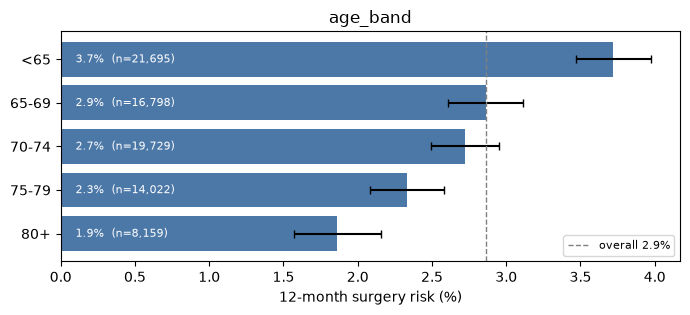

,age_band,n,surgeries,p_12m,ci_low,ci_high,p_km,relative_risk
0,<65,21695,807,0.0372,0.0347,0.0397,0.0388,1.2976
1,65-69,16798,481,0.0286,0.0261,0.0312,0.0300,0.9989
2,70-74,19729,537,0.0272,0.0249,0.0295,0.0287,0.9495
3,75-79,14022,327,0.0233,0.0208,0.0258,0.0247,0.8135
4,80+,8159,152,0.0186,0.0157,0.0216,0.0200,0.6499


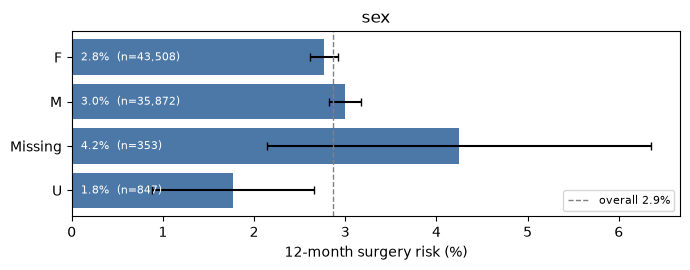

,sex,n,surgeries,p_12m,ci_low,ci_high,p_km,relative_risk
0,F,43508,1205,0.0277,0.0262,0.0292,0.0292,0.9661
1,M,35872,1075,0.0300,0.0282,0.0317,0.0314,1.0454
2,Missing,353,15,0.0425,0.0215,0.0635,0.0444,1.4823
3,U,847,15,0.0177,0.0088,0.0266,0.0183,0.6178


In [8]:
for col in ["age_band", "sex"]:
    t = risk_by(panel, col)
    plot_risk(t, col)
    display(t)

In [9]:
risk_grid(panel, "age_band", "sex")

sex,F,M,Missing,U
age_band,,,,
<65,11388,10027,86,194
65-69,9004,7539,69,186
70-74,10989,8428,84,228
75-79,7611,6169,87,155
80+,4392,3657,27,83


sex,F,M,Missing,U
age_band,,,,
<65,3.6%,3.9%,-,-
65-69,2.8%,2.9%,-,-
70-74,2.8%,2.5%,-,2.6%
75-79,1.9%,2.8%,-,-
80+,1.8%,2.0%,-,-


## Weight

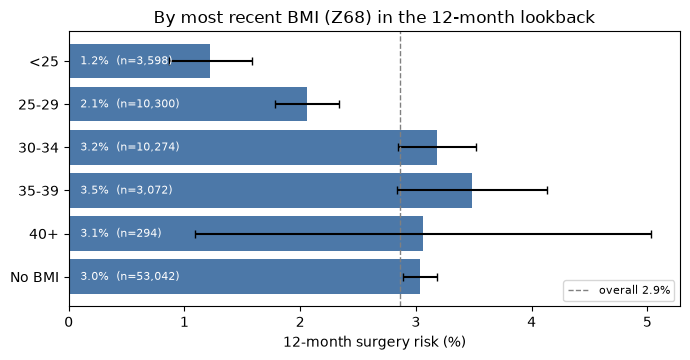

,bmi_band,n,surgeries,p_12m,ci_low,ci_high,p_km,relative_risk
0,<25,3598,44,0.0122,0.0086,0.0158,0.0129,0.4266
1,25-29,10300,212,0.0206,0.0178,0.0233,0.0217,0.7180
2,30-34,10274,327,0.0318,0.0284,0.0352,0.0334,1.1103
3,35-39,3072,107,0.0348,0.0283,0.0413,0.0366,1.2150
4,40+,294,9,0.0306,0.0109,0.0503,0.0325,1.0679
5,No BMI,53042,1611,0.0304,0.0289,0.0318,0.0320,1.0595


,flag,prevalence,n_yes,p_yes,p_no,risk_ratio
0,obesity_dx,0.1655,13339,0.0292,0.0286,1.0239


obesity_dx,no_E66,has_E66
bmi_band,,
<25,1.0000,0.0000
25-29,1.0000,0.0000
30-34,0.4924,0.5076
35-39,0.4906,0.5094
40+,0.5986,0.4014
No BMI,0.8786,0.1214


In [10]:
t = risk_by(panel, "bmi_band")
plot_risk(t, "bmi_band", "By most recent BMI (Z68) in the 12-month lookback")
display(t)
display(flag_table(panel, ["obesity_dx"]))
pd.crosstab(panel.bmi_band, panel.obesity_dx, normalize="index").rename(columns={True: "has_E66", False: "no_E66"})

In [11]:
risk_grid(panel, "age_band", "bmi_band")

bmi_band,<25,25-29,30-34,35-39,40+,No BMI
age_band,,,,,,
<65,927,2928,2805,739,86,14210
65-69,771,2064,2117,606,57,11183
70-74,940,2449,2432,812,51,13045
75-79,602,1793,1781,591,63,9192
80+,351,1035,1113,310,37,5313


bmi_band,<25,25-29,30-34,35-39,40+,No BMI
age_band,,,,,,
<65,1.1%,2.6%,4.7%,4.1%,-,3.9%
65-69,1.3%,2.1%,3.2%,5.9%,-,2.9%
70-74,1.2%,1.9%,2.8%,2.8%,-,3.0%
75-79,0.8%,1.8%,2.2%,1.7%,-,2.6%
80+,2.3%,1.2%,1.8%,2.6%,-,2.0%


In [12]:
risk_grid(panel, "sex", "bmi_band")

bmi_band,<25,25-29,30-34,35-39,40+,No BMI
sex,,,,,,
F,1938,5533,5621,1671,162,28583
M,1609,4597,4502,1347,124,23693
Missing,11,58,41,16,0,227
U,40,112,110,38,8,539


bmi_band,<25,25-29,30-34,35-39,40+,No BMI
sex,,,,,,
F,1.2%,2.0%,3.2%,3.5%,-,2.9%
M,1.2%,2.1%,3.2%,3.4%,-,3.2%
Missing,-,-,-,-,-,3.5%
U,-,-,-,-,-,1.3%


## Health conditions

,flag,prevalence,n_yes,p_yes,p_no,risk_ratio
2,heart_disease,0.1458,11751,0.0324,0.0280,1.1569
4,ckd,0.1434,11554,0.0310,0.0283,1.0957
5,depression_anxiety,0.2603,20979,0.0288,0.0286,1.0081
3,copd,0.1436,11569,0.0285,0.0287,0.9942
0,diabetes,0.1426,11490,0.0278,0.0288,0.9634
1,hypertension,0.1436,11568,0.0277,0.0288,0.9628
7,osteoporosis,0.1426,11491,0.0276,0.0288,0.9563
6,smoker,0.1441,11610,0.0276,0.0289,0.9553


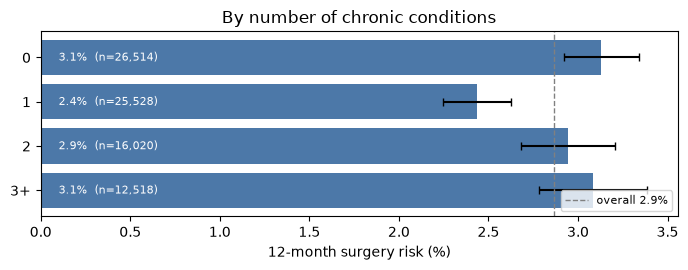

,n_conditions,n,surgeries,p_12m,ci_low,ci_high,p_km,relative_risk
0,0,26514,830,0.0313,0.0292,0.0334,0.0328,1.0920
1,1,25528,622,0.0244,0.0225,0.0263,0.0256,0.8499
2,2,16020,472,0.0295,0.0268,0.0321,0.0311,1.0278
3,3+,12518,386,0.0308,0.0278,0.0339,0.0328,1.0756


In [13]:
t = flag_table(panel, list(CONDITIONS))
display(t)
t = risk_by(panel, "n_conditions")
plot_risk(t, "n_conditions", "By number of chronic conditions")
t

In [14]:
risk_grid(panel, "age_band", "n_conditions")

n_conditions,0,1,2,3+
age_band,,,,
<65,8639,7209,3766,2081
65-69,5998,5371,3244,2185
70-74,6176,6350,4062,3141
75-79,3758,4334,3011,2919
80+,1875,2203,1901,2180


n_conditions,0,1,2,3+
age_band,,,,
<65,3.6%,3.1%,4.7%,4.6%
65-69,3.2%,2.4%,2.8%,3.2%
70-74,3.0%,2.2%,2.4%,3.7%
75-79,2.6%,2.1%,2.4%,2.2%
80+,2.1%,1.8%,1.7%,1.9%


## Where the patient is on the spine path

These features describe the patient's clinical state rather than demographics. They're included because they will probably dominate the model, and they show what being "earlier in the journey" costs in risk.

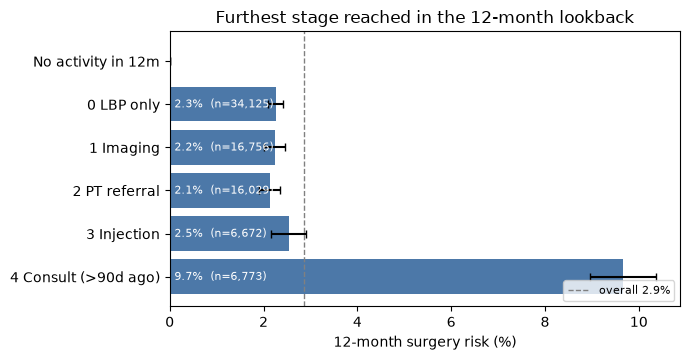

,stage_label,n,surgeries,p_12m,ci_low,ci_high,p_km,relative_risk
0,No activity in 12m,225,0,0.0000,0.0000,0.0000,0.0000,0.0000
1,0 LBP only,34125,771,0.0226,0.0210,0.0242,0.0239,0.7881
2,1 Imaging,16756,375,0.0224,0.0201,0.0246,0.0235,0.7807
3,2 PT referral,16029,341,0.0213,0.0190,0.0235,0.0225,0.7421
4,3 Injection,6672,169,0.0253,0.0216,0.0291,0.0269,0.8836
5,4 Consult (>90d ago),6773,654,0.0966,0.0895,0.1036,0.1005,3.3683


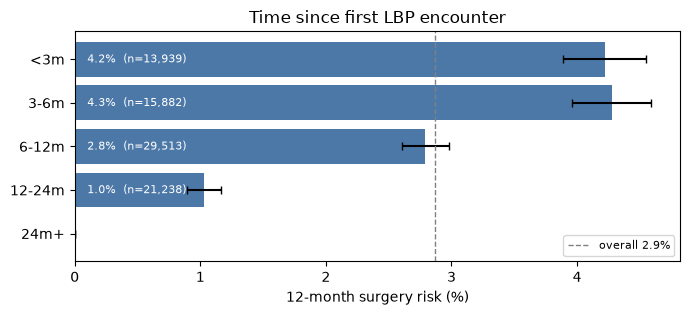

,lbp_tenure,n,surgeries,p_12m,ci_low,ci_high,p_km,relative_risk
0,<3m,13939,588,0.0422,0.0388,0.0455,0.0444,1.4715
1,3-6m,15882,679,0.0428,0.0396,0.0459,0.0444,1.4914
2,6-12m,29513,824,0.0279,0.0260,0.0298,0.0292,0.9739
3,12-24m,21238,219,0.0103,0.0090,0.0117,0.0110,0.3597
4,24m+,8,0,0.0000,0.0000,0.0000,0.0000,0.0000


In [15]:
for col, title in [("stage_label", "Furthest stage reached in the 12-month lookback"), ("lbp_tenure", "Time since first LBP encounter")]:
    t = risk_by(panel, col)
    plot_risk(t, col, title)
    display(t)

In [16]:
flag_table(panel, list(SPINE_DX) + ["mri", "injection", "pt_claims", "prior_program"])

,flag,prevalence,n_yes,p_yes,p_no,risk_ratio
6,injection,0.0998,8044,0.0388,0.0275,1.4081
5,mri,0.2597,20927,0.0321,0.0275,1.1670
8,prior_program,0.2764,22275,0.0295,0.0283,1.0426
2,neurogenic_claudication,0.5127,41314,0.0286,0.0288,0.9942
4,disc_degeneration,0.5137,41397,0.0284,0.0289,0.9833
7,pt_claims,0.3588,28911,0.0283,0.0289,0.9817
3,spondylolisthesis,0.5151,41506,0.0283,0.0290,0.9763
0,radiculopathy,0.7622,61418,0.0277,0.0318,0.8695
1,stenosis,0.7603,61269,0.0276,0.0320,0.8648


In [17]:
risk_grid(panel, "stage_label", "age_band")

age_band,<65,65-69,70-74,75-79,80+
stage_label,,,,,
No activity in 12m,63,50,61,24,27
0 LBP only,9228,7270,8387,5916,3256
1 Imaging,4529,3348,4129,2964,1752
2 PT referral,4261,3391,3871,2796,1672
3 Injection,1787,1394,1613,1134,724
4 Consult (>90d ago),1827,1345,1668,1188,728


age_band,<65,65-69,70-74,75-79,80+
stage_label,,,,,
No activity in 12m,-,-,-,-,-
0 LBP only,3.1%,2.4%,1.9%,1.7%,1.4%
1 Imaging,2.3%,2.3%,2.6%,2.2%,1.1%
2 PT referral,2.9%,1.7%,2.2%,1.3%,2.2%
3 Injection,3.5%,2.0%,3.0%,2.1%,0.8%
4 Consult (>90d ago),12.8%,10.5%,8.0%,8.4%,6.0%


In [18]:
risk_grid(panel, "stage_label", "bmi_band")

bmi_band,<25,25-29,30-34,35-39,40+,No BMI
stage_label,,,,,,
No activity in 12m,23,43,24,11,0,124
0 LBP only,1630,4442,4421,1223,92,22317
1 Imaging,731,2133,2039,674,56,11123
2 PT referral,697,2092,2039,667,74,10460
3 Injection,254,836,810,247,29,4496
4 Consult (>90d ago),263,754,941,250,43,4522


bmi_band,<25,25-29,30-34,35-39,40+,No BMI
stage_label,,,,,,
No activity in 12m,-,-,-,-,-,-
0 LBP only,1.2%,1.6%,2.6%,2.9%,-,2.4%
1 Imaging,0.8%,1.7%,1.7%,3.3%,-,2.5%
2 PT referral,0.6%,1.6%,2.3%,2.2%,-,2.3%
3 Injection,0.8%,2.2%,3.8%,2.8%,-,2.5%
4 Consult (>90d ago),4.9%,7.2%,10.4%,11.2%,-,10.0%


## How concentrated is the risk?

A crude version of what a ranking model will exploit. Each snapshot is scored with a hand-built rule: the KM risk of its stage × spine-diagnosis cell. The question is what share of surgeries falls in the top-k% of snapshots. This isn't a model; it's an upper bound on how simple the ranking could be.

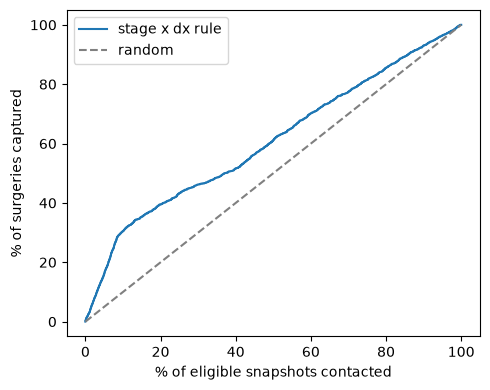

top 5%: captures 16% of surgeries, risk in group 9.2%
top 10%: captures 30% of surgeries, risk in group 8.7%
top 20%: captures 40% of surgeries, risk in group 5.7%
top 30%: captures 46% of surgeries, risk in group 4.4%


In [19]:
panel["dx_any"] = panel[["radiculopathy", "stenosis", "spondylolisthesis"]].any(axis=1)
cell = risk_by(panel, ["stage_label", "dx_any"])[["stage_label", "dx_any", "p_12m"]]
scored = panel.merge(cell, on=["stage_label", "dx_any"]).sort_values("p_12m", ascending=False)
scored["cum_share_patients"] = np.arange(1, len(scored) + 1) / len(scored)
scored["cum_share_surgeries"] = scored.event.cumsum() / scored.event.sum()

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(scored.cum_share_patients * 100, scored.cum_share_surgeries * 100, label="stage x dx rule")
ax.plot([0, 100], [0, 100], "--", color="grey", label="random")
ax.set_xlabel("% of eligible snapshots contacted")
ax.set_ylabel("% of surgeries captured")
ax.legend()
plt.tight_layout()
plt.show()
for k in [0.05, 0.1, 0.2, 0.3]:
    top = scored[scored.cum_share_patients <= k]
    print(f"top {k:.0%}: captures {top.event.sum() / scored.event.sum():.0%} of surgeries, risk in group {top.event.mean():.1%}")

## Takeaways

The target, surgery while still covered within 12 months, is **2.87%** (2,310 surgeries in 80,580 snapshots). For comparison:
- Kaplan–Meier, the risk if patients stayed covered: 3.02%.
- Dropping leavers (a complete-case rate): 3.36%. This overstates risk under either framing.
- 15% of snapshots leave coverage without surgery before 12 months.
- Counting null-status surgeries adds 90 surgeries over the Performed-only label.

**What separates risk:**
- **Prior surgical consult (more than 90 days ago): 9.7% vs about 2.1–2.5% for every earlier stage.** Imaging, PT referral and injection barely move risk on their own; the consult is the step change.
- **Time since first LBP encounter:** about 4.2% in the first 6 months, 2.8% at 6–12 months, 1.0% after 12 months. Use it in the model as bands **capped at 12m+**. An uncapped version would extrapolate, because the 2026-07 population is entirely 12+ months out and half are 24+. Left-truncation of the first visit only blurs the <6m and 6–12m bands. (An earlier version of this note said the feature couldn't be used. Leaving it out made the sandbox models over-predict 2025-07 by 30%, and 2.6× for 12m+ patients; see `sandbox/README.md`.)
- **BMI:** 1.2% (<25) → 2.1% (25–29) → 3.2–3.5% (30+). This is the clearest demographic gradient. Two thirds of snapshots have no Z68 code, and the E66 obesity diagnosis carries no signal on its own (risk ratio 1.0).
- **Age:** risk falls steadily from 3.7% (<65, disability coverage) to 1.9% (80+).
- **Injection (risk ratio 1.41) and MRI (1.17)** add modest lift.

**What doesn't:** sex, chronic conditions (individually or as a count), spine diagnosis codes (flat risk at 50–76% prevalence), PT claims, and prior program enrollment.

**Implications for the model:**
- The label is surgery before min(t + 12 months, coverage_end), fitted with a plain logistic regression on all eligible snapshots. No censoring weights are needed because leaving coverage is a competing event.
- **Risk drifts down over index dates (3.75% → 2.16%)** because the cohort is closed and ages past its first year. Time since first LBP visit explains essentially all of it: with the capped bands, predicted ÷ observed is 0.97–1.03 at every index date.
- A crude stage × diagnosis rule puts 30% of surgeries in the top 10% of snapshots (risk 8.7% vs 2.87% overall).
- **The tension with "earlier":** the strongest signal (a prior consult) is the latest stage, so ranking on risk alone pulls toward consulted patients.